# Phenology status and Kc matrix

This notebook explains how the crop phenology state and the crop coefficient (Kc) matrix are built in the IWR model.

The phenology state is a seasonal label for each dekad:
- `0` = inactive
- `1` = growing
- `2` = maximum
- `3` = senescence

The Kc matrix is then derived from this state. During the growing phase, Kc increases linearly from `kc_initial` to `kc_max`; during the maximum phase it remains at `kc_max`; and during senescence it decreases from `kc_max` to `kc_sen`. The inactive period keeps a low or zero Kc value.

This example builds a simple synthetic phenology year and visualizes the resulting daily Kc curve.

In [10]:
import os

for key in ["PROJ_LIB", "PROJ_DATA", "GDAL_DATA"]:
    os.environ.pop(key, None)

print("Cleared stale PROJ/GDAL environment variables before rasterio import.")


Cleared stale PROJ/GDAL environment variables before rasterio import.


In [11]:
from pathlib import Path
import sys
import os
import rasterio

project_root = Path.cwd().resolve()
src_path = project_root / "src"
if str(src_path) not in sys.path:
    sys.path.insert(0, str(src_path))

import numpy as np
import matplotlib.pyplot as plt

from iwr.crops import Crop
from iwr.phenology import Phenology, PHENOLOGY_INACTIVE, PHENOLOGY_GROWING, PHENOLOGY_MAXIMUM, PHENOLOGY_SENESCENCE

In [12]:
# Create a simple 1x1 valid mask and a seasonal phenology cycle
valid_mask = np.ones((1, 1), dtype=np.uint8)
phenology = Phenology(valid_mask=valid_mask)

state = np.zeros((36, 1, 1), dtype=np.uint8)
state[0:5, 0, 0] = PHENOLOGY_INACTIVE
state[5:15, 0, 0] = PHENOLOGY_GROWING
state[15:24, 0, 0] = PHENOLOGY_MAXIMUM
state[24:30, 0, 0] = PHENOLOGY_SENESCENCE
state[30:36, 0, 0] = PHENOLOGY_INACTIVE

phenology.state.values[:, 0, 0] = state[:, 0, 0]

crop = Crop.from_name("wheat")
kc = phenology.build_Kc_from_crop(crop)
print(crop)
print("Phenology state by dekad:", phenology.state.values[:, 0, 0])
print("Kc values for the year:", np.round(kc.isel(row=0, col=0).values[:20], 3))

Crop(name='wheat', root_max_depth=1.0, kc_initial=0.3, kc_max=1.15, kc_sen=0.4, p=0.55, crop_raster=None)
Phenology state by dekad: [0 0 0 0 0 1 1 1 1 1 1 1 1 1 1 2 2 2 2 2 2 2 2 2 3 3 3 3 3 3 0 0 0 0 0 0]
Kc values for the year: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]


kc shape: (366, 1, 1)
first Kc values: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]


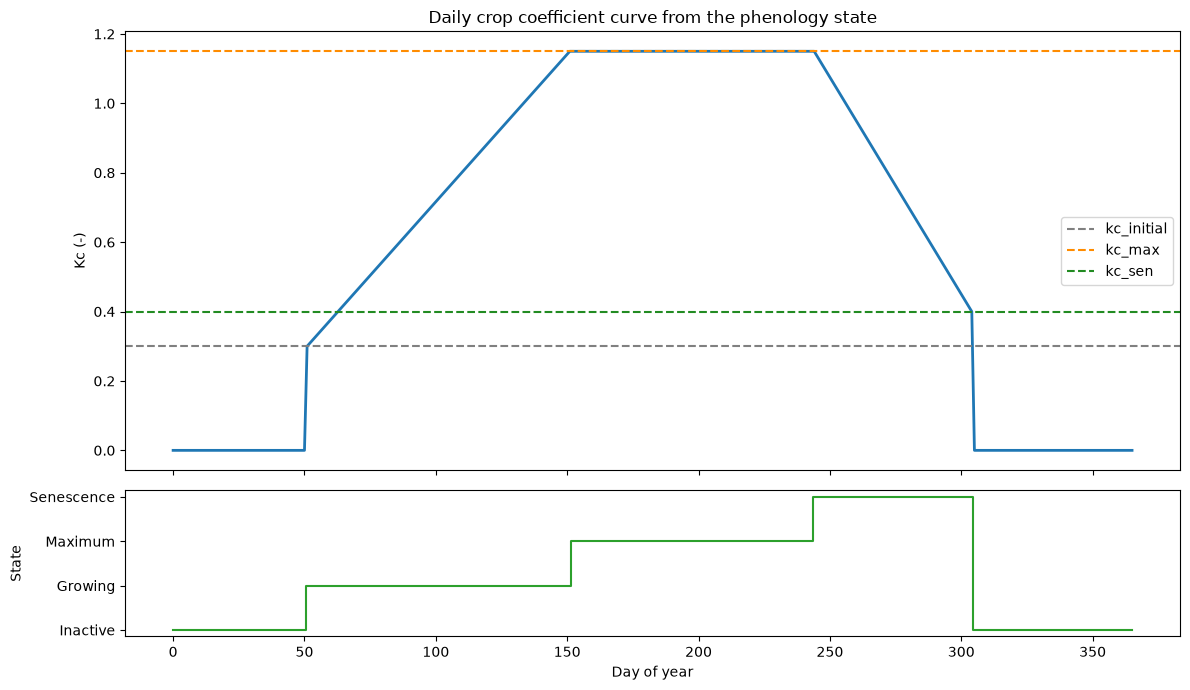

In [13]:
%matplotlib inline
import matplotlib.pyplot as plt

print("kc shape:", kc.shape)
print("first Kc values:", kc.isel(row=0, col=0).values[:10])

daily_kc = kc.isel(row=0, col=0).values
daily_state = phenology._state_to_daily().reshape(-1, 1, 1)[..., 0, 0]

fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True, height_ratios=[3, 1])

axes[0].plot(daily_kc, color="tab:blue", linewidth=2)
axes[0].axhline(crop.kc_initial, color="gray", linestyle="--", label="kc_initial")
axes[0].axhline(crop.kc_max, color="darkorange", linestyle="--", label="kc_max")
axes[0].axhline(crop.kc_sen, color="forestgreen", linestyle="--", label="kc_sen")
axes[0].set_ylabel("Kc (-)")
axes[0].set_title("Daily crop coefficient curve from the phenology state")
axes[0].legend()

axes[1].step(np.arange(len(daily_state)), daily_state, where="mid", color="tab:green")
axes[1].set_xlabel("Day of year")
axes[1].set_ylabel("State")
axes[1].set_yticks([PHENOLOGY_INACTIVE, PHENOLOGY_GROWING, PHENOLOGY_MAXIMUM, PHENOLOGY_SENESCENCE])
axes[1].set_yticklabels(["Inactive", "Growing", "Maximum", "Senescence"])

plt.tight_layout()
plt.show()

### Raster workflow: loading the reference grid and generating aligned phenology rasters

This section prepares the spatial reference for the phenology data. The `static_folder` contains the fixed rasters used to align all crop and phenology layers to the same grid. In this example, `working_grid_3035_1km_precip_valid.tif` is the reference raster: it defines the valid mask and the spatial extent, resolution, CRS, and pixel alignment that every phenology layer must match.

The workflow is:
1. open the reference raster and read its first band as `working_grid`
2. create the output folder where the aligned SPAM phenology files will be stored
3. call `Phenology.create_spam_dataset(...)` to download or read the raw phenology layers, reproject/align them to the reference grid, and write the aligned GeoTIFFs
4. print the dictionary of generated paths so the aligned files can be loaded into `Phenology.from_spam(...)`

This step is important because the model expects all phenology inputs to share the same grid and valid-mask geometry. Without this alignment, pixel positions and crop stages would not correspond to the same agricultural cells.


In [14]:
static_folder = "/home/fremen/data/projects/DAO/00_static"
working_grid_path = f"{static_folder}/working_grid_3035_1km_precip_valid.tif"

# Load the valid mask and soil texture rasters
working_grid_src = rasterio.open(working_grid_path)
working_grid = working_grid_src.read(1)  # Read the first band

output_path = Path(static_folder) / "ASAP_auto"
os.makedirs(output_path, exist_ok=True)
reference_raster_path = f"{static_folder}/working_grid_3035_1km_precip_valid.tif"

pheno_paths = Phenology.create_asap_dataset(output_path=output_path, reference_raster_path=reference_raster_path)

print(pheno_paths)

Reference CRS: EPSG:3035
Reference shape: (256, 285)
Already processed: /home/fremen/data/projects/DAO/00_static/ASAP_auto/phenos1_v05_aligned.tif
Already processed: /home/fremen/data/projects/DAO/00_static/ASAP_auto/phenos2_v05_aligned.tif
Already processed: /home/fremen/data/projects/DAO/00_static/ASAP_auto/phenom1_v05_aligned.tif
Already processed: /home/fremen/data/projects/DAO/00_static/ASAP_auto/phenom2_v05_aligned.tif
Already processed: /home/fremen/data/projects/DAO/00_static/ASAP_auto/phenoe1_v05_aligned.tif
Already processed: /home/fremen/data/projects/DAO/00_static/ASAP_auto/phenoe2_v05_aligned.tif
Already processed: /home/fremen/data/projects/DAO/00_static/ASAP_auto/phenosen1_v05_aligned.tif
Already processed: /home/fremen/data/projects/DAO/00_static/ASAP_auto/phenosen2_v05_aligned.tif
Already processed: /home/fremen/data/projects/DAO/00_static/ASAP_auto/phenonseasons_v05_aligned.tif
{'phenos1': '/home/fremen/data/projects/DAO/00_static/ASAP_auto/phenos1_v05_aligned.tif', '

In [15]:
# load phenology from ASAP
phenoe1 = rasterio.open(pheno_paths["phenoe1"]).read(1)
phenoe2 = rasterio.open(pheno_paths["phenoe2"]).read(1)
phenom1 = rasterio.open(pheno_paths["phenom1"]).read(1)
phenom2 = rasterio.open(pheno_paths["phenom2"]).read(1)
phenonseasons = rasterio.open(pheno_paths["phenonseasons"]).read(1)
phenos1 = rasterio.open(pheno_paths["phenos1"]).read(1)
phenos2 = rasterio.open(pheno_paths["phenos2"]).read(1)
phenosen1 = rasterio.open(pheno_paths["phenosen1"]).read(1)
phenosen2 = rasterio.open(pheno_paths["phenosen2"]).read(1)

phenology = Phenology.from_asap(
    valid_mask=working_grid,
    phenoe1=phenoe1,
    phenoe2=phenoe2,
    phenom1=phenom1,
    phenom2=phenom2,
    phenonseasons=phenonseasons,
    phenos1=phenos1,
    phenos2=phenos2,
    phenosen1=phenosen1,
    phenosen2=phenosen2
)


In [16]:
print("Phenology object created from aligned ASAP rasters")
print("Valid mask shape:", working_grid.shape)
print("Phenology state shape:", phenology.state.shape)
print("Kc matrix shape:", phenology.Kc_matrix.shape)
print("State labels in the first cell:", phenology.state.isel(row=0, col=0).values)
print("First daily Kc values in the first cell:", np.round(phenology.Kc_matrix.isel(row=0, col=0).values[:10], 3))
print(phenology)


Phenology object created from aligned ASAP rasters
Valid mask shape: (256, 285)
Phenology state shape: (36, 256, 285)
Kc matrix shape: (366, 256, 285)
State labels in the first cell: [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
First daily Kc values in the first cell: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
Phenology(valid_mask=array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]], shape=(256, 285), dtype=uint8), time_index=None, crop=None, sowing_date=None, phenoe1=array([[255, 255, 255, ..., 255, 255, 255],
       [255, 255, 255, ..., 255, 255, 255],
       [255, 255, 255, ..., 255, 255, 255],
       ...,
       [255, 255, 255, ..., 255, 255, 255],
       [255, 255, 255, ..., 255, 255, 255],
       [255, 255, 255, ..., 255, 255, 255]], shape=(256, 285), dtype=uint8), phenoe2=array([[255, 255, 255, ..., 255, 255, 255

### How `build_Kc_from_crop` works

`build_Kc_from_crop` takes a crop definition such as maize or wheat and uses the seasonal phenology state to build the full annual Kc matrix. The method reads the state labels stored in `phenology.state`, converts the 36-dekad cycle into a daily sequence, and then interpolates the crop coefficient values between the crop-specific phases:

- `kc_initial`: early growth phase
- `kc_max`: peak canopy / maximum crop coefficient
- `kc_sen`: late-season senescence phase

The crop coefficient stays low or near zero in the inactive period, rises during the growing period, remains at `kc_max` during the maximum phase, and declines toward `kc_sen` during senescence. The final result is a daily Kc series saved in `phenology.Kc_matrix`.

The next cell repeats the same logic for maize, which is useful when you want to create a maize-specific Kc curve instead of the wheat example.


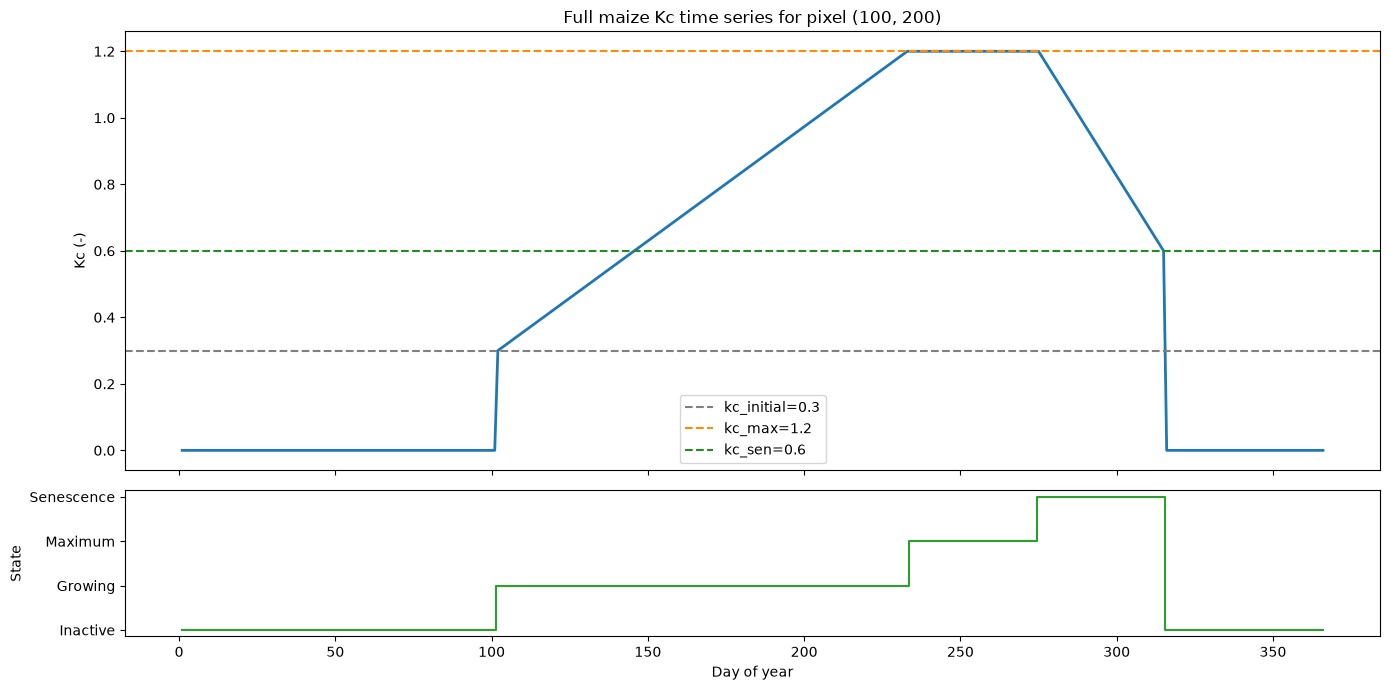

Pixel Kc first 20 values: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
Daily state first 20 values: [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


In [20]:
maize_crop = Crop.from_name("maize")
maize_kc = phenology.build_Kc_from_crop(maize_crop)

# Full Kc time series for a single pixel: row 100, col 200
# This is the annual curve used in the model for one agricultural cell.
row_idx = 100
col_idx = 200
pixel_kc = maize_kc.isel(row=row_idx, col=col_idx).values
pixel_state = phenology.state.isel(row=row_idx, col=col_idx).values
daily_state = phenology._state_to_daily()[:, row_idx, col_idx]

day_index = np.arange(1, len(pixel_kc) + 1)

fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True, height_ratios=[3, 1])

axes[0].plot(day_index, pixel_kc, color="tab:blue", linewidth=2)
axes[0].axhline(maize_crop.kc_initial, color="gray", linestyle="--", label=f"kc_initial={maize_crop.kc_initial}")
axes[0].axhline(maize_crop.kc_max, color="darkorange", linestyle="--", label=f"kc_max={maize_crop.kc_max}")
axes[0].axhline(maize_crop.kc_sen, color="forestgreen", linestyle="--", label=f"kc_sen={maize_crop.kc_sen}")
axes[0].set_title(f"Full maize Kc time series for pixel ({row_idx}, {col_idx})")
axes[0].set_ylabel("Kc (-)")
axes[0].legend()

axes[1].step(day_index, daily_state, where="mid", color="tab:green")
axes[1].set_xlabel("Day of year")
axes[1].set_ylabel("State")
axes[1].set_yticks([PHENOLOGY_INACTIVE, PHENOLOGY_GROWING, PHENOLOGY_MAXIMUM, PHENOLOGY_SENESCENCE])
axes[1].set_yticklabels(["Inactive", "Growing", "Maximum", "Senescence"])

plt.tight_layout()
plt.show()

print("Pixel Kc first 20 values:", np.round(pixel_kc[:20], 3))
print("Daily state first 20 values:", daily_state[:20])


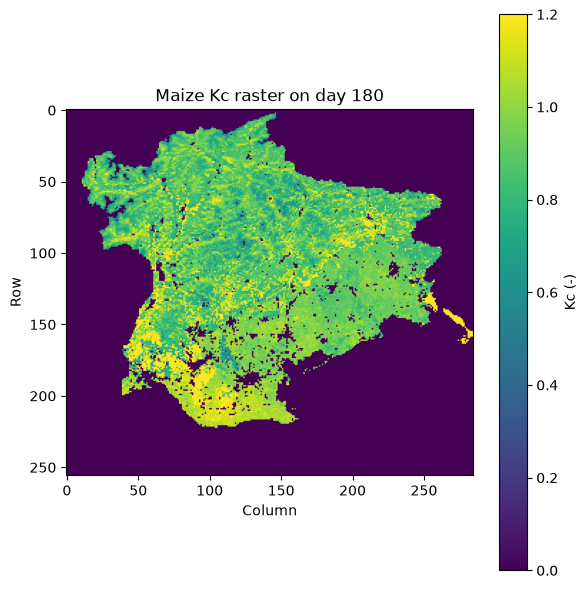

In [ ]:
# Show the full Kc raster as a spatial heatmap for one day of the year
selected_day = 180
kc_raster = maize_kc.isel(time=selected_day - 1).values

fig, ax = plt.subplots(figsize=(6, 6))
img = ax.imshow(kc_raster, cmap="viridis")
ax.set_title(f"Maize Kc raster on day {selected_day}")
ax.set_xlabel("Column")
ax.set_ylabel("Row")
fig.colorbar(img, ax=ax, label="Kc (-)")
plt.tight_layout()
plt.show()
